In [37]:
# Importing all of the relevant programs we will need for this project. 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 
import csv 
import numpy as np
import plotly.express as px

# Reading in the data set and displaing the first 5 rows of the data set. 
# Fixed a UnicodeError: we used the csv module from Python to process the code line by line 
# without worrying about whether a row has 13, 14, or 17 fields 
# due to certain inconsistencies in the number of columns in some of the rows. 

df = pd.DataFrame(
    list(csv.reader(open("kickstarter.csv", encoding="cp1252")))
)

## Overview of the data frame, including the numeber of rows and columns, data types, and memory usage. 

display(df.head())
print("Dataset shape:", df.shape)
display(df.info())
display(df.describe(include="all").T)

# Dropping columns with missing values
df = df.dropna(axis=1)

#Looking at 13, 14, 15, 16 differences from the rest

print("Testing") 

/var/folders/cx/1bd5ng0x13sfdp4d82d7wfk40000gn/T/ipykernel_32827/2057580381.py:14: Pandas4Warning: Constructing a DataFrame from a list of sequences with mismatched lengths is deprecated and will raise in a future version. The shorter sequences are currently padded with NaN; make all sequences the same length before constructing instead.
  df = pd.DataFrame(


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,NaN,NaN,NaN,NaN
1,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09 11:36:00,1000,2015-08-11 12:12:28,0,failed,0,GB,0,NaN,NaN,NaN,NaN
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26 00:20:50,45000,2013-01-12 00:20:50,220,failed,3,US,220,NaN,NaN,NaN,NaN
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16 04:24:11,5000,2012-03-17 03:24:11,1,failed,1,US,1,NaN,NaN,NaN,NaN
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29 01:00:00,19500,2015-07-04 08:35:03,1283,canceled,14,US,1283,NaN,NaN,NaN,NaN


Dataset shape: (323751, 17)
<class 'pandas.DataFrame'>
RangeIndex: 323751 entries, 0 to 323750
Data columns (total 17 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   0       323751 non-null  str  
 1   1       323751 non-null  str  
 2   2       323751 non-null  str  
 3   3       323751 non-null  str  
 4   4       323751 non-null  str  
 5   5       323751 non-null  str  
 6   6       323751 non-null  str  
 7   7       323751 non-null  str  
 8   8       323751 non-null  str  
 9   9       323751 non-null  str  
 10  10      323751 non-null  str  
 11  11      323751 non-null  str  
 12  12      323751 non-null  str  
 13  13      625 non-null     str  
 14  14      624 non-null     str  
 15  15      624 non-null     str  
 16  16      624 non-null     str  
dtypes: str(17)
memory usage: 42.0 MB


None

,count,unique,top,freq
0,323751,323751,ID,1
1,323751,321617,New EP/Music Development,41
2,323751,772,Product Design,17477
3,323751,121,Film & Video,57679
4,323751,38,USD,260298
5,323751,294814,USD,508
6,323751,8189,5000,25520
7,323751,322799,5000,60
8,323751,55599,0,45784
9,323751,411,failed,168221


Testing


In [38]:

# Fixing the category issue here where it was originally an integer, and it is now its actual label. 
df_clean = df.copy() 
df.head() #Will stop here, and take a look at the summary statistics at a later time today! 

#you can only consider rows that have above a certain threshold. 
#or bin the small categories called others. 
#df["category"].value_counts() #this will give you the counts of each category.



,0,1,2,3,4,5,6,7,8,9,10,11,12
0,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged
1,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09 11:36:00,1000,2015-08-11 12:12:28,0,failed,0,GB,0
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26 00:20:50,45000,2013-01-12 00:20:50,220,failed,3,US,220
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16 04:24:11,5000,2012-03-17 03:24:11,1,failed,1,US,1
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29 01:00:00,19500,2015-07-04 08:35:03,1283,canceled,14,US,1283


In [39]:
# Information about the data frame, including the number of rows and columns, data types, and memory usage.
df.columns 
df.columns = df.iloc[0]  # Set the first row as column names
df = df.iloc[1:]  # Remove the first row

In [40]:
df.head()
df.columns 

# Remove leading and trailing spaces from column names
df.columns = df.columns.str.strip()

# Check the cleaned column names
print(df.columns.tolist())

['ID', 'name', 'category', 'main_category', 'currency', 'deadline', 'goal', 'launched', 'pledged', 'state', 'backers', 'country', 'usd pledged']


In [41]:
print(df.head())
print(df.columns)


0          ID                                               name  \
1  1000002330                    The Songs of Adelaide & Abullah   
2  1000004038                                     Where is Hank?   
3  1000007540  ToshiCapital Rekordz Needs Help to Complete Album   
4  1000011046  Community Film Project: The Art of Neighborhoo...   
5  1000014025                               Monarch Espresso Bar   

0        category main_category currency             deadline   goal  \
1          Poetry    Publishing      GBP  2015-10-09 11:36:00   1000   
2  Narrative Film  Film & Video      USD  2013-02-26 00:20:50  45000   
3           Music         Music      USD  2012-04-16 04:24:11   5000   
4    Film & Video  Film & Video      USD  2015-08-29 01:00:00  19500   
5     Restaurants          Food      USD  2016-04-01 13:38:27  50000   

0             launched pledged       state backers country usd pledged  
1  2015-08-11 12:12:28       0      failed       0      GB           0  
2  2013-01-1

In [42]:
top_10_categories = df['category'].value_counts().head(10).index
top_10_categories 

filtered_df = df[df['category'].isin(top_10_categories)]
filtered_df 

#What percentage do the categories take up in the data set. 

0,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16 04:24:11,5000,2012-03-17 03:24:11,1,failed,1,US,1
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29 01:00:00,19500,2015-07-04 08:35:03,1283,canceled,14,US,1283
6,1000023410,Support Solar Roasted Coffee & Green Energy! ...,Food,Food,USD,2014-12-21 18:30:44,1000,2014-12-01 18:30:44,1205,successful,16,US,1205
8,1000034518,SPIN - Premium Retractable In-Ear Headphones w...,Product Design,Design,USD,2014-05-29 18:14:43,125000,2014-04-24 18:14:43,8233,canceled,58,US,8233
9,100004195,STUDIO IN THE SKY - A Documentary Feature Film...,Documentary,Film & Video,USD,2014-08-10 21:55:48,65000,2014-07-11 21:55:48,6240.57,canceled,43,US,6240.57
...,...,...,...,...,...,...,...,...,...,...,...,...,...
323736,999934908,The Manual Bar Blade,Product Design,Design,USD,2015-12-15 06:59:00,3500,2015-11-23 07:33:14,6169,successful,120,US,6169
323740,999955533,Cards and Chit Network Season 2! (Canceled),Tabletop Games,Games,USD,2016-02-23 16:03:27,500,2016-01-24 16:03:27,121,canceled,5,US,121
323743,999971898,Beach Wrestling Documentary,Documentary,Film & Video,NOK,2015-04-28 21:30:33,20000,2015-03-29 21:30:33,21500,successful,36,NO,2698.974335
323744,999972264,Islanda,Documentary,Film & Video,USD,2012-03-16 03:31:10,1700,2012-02-15 04:31:10,25,failed,1,US,25


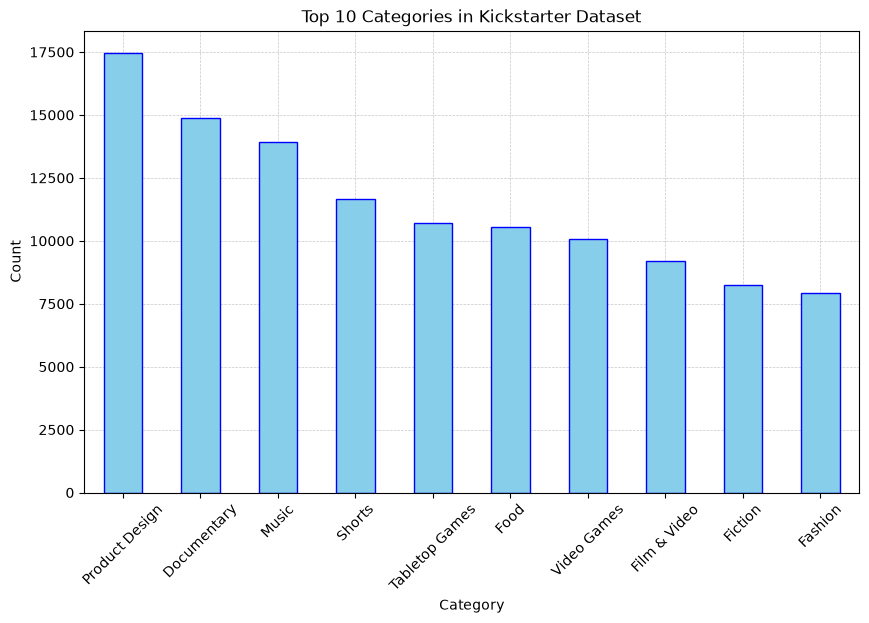

In [43]:
# Filtering the DataFrame to include only the top 10 categories based on their counts.
filtered_df = df[df['category'].isin(top_10_categories)] 
filtered_df

#Needs to show the 10 categories and their counts.

ax = filtered_df['category'].value_counts().plot(kind='bar', figsize=(10, 6), color='skyblue', edgecolor='blue')
plt.title('Top 10 Categories in Kickstarter Dataset')
plt.xlabel('Category')
plt.ylabel('Count') 


ax.grid(True, which='major',axis='both', linestyle='--',linewidth=0.5, alpha=0.7)
plt.xticks(rotation=45) 
ax.set_axisbelow(True)


In [44]:
#Filtering to the Top 5 Most Popular Main Categories in the Kickstarter Dataset.

top_5_main_categories = df['main_category'].value_counts().head(5).index
top_5_main_categories 

filtered_df = df[df['main_category'].isin(top_5_main_categories)]
filtered_df 

#Future Question: What percentage do the main categories categories take up in the data set?

0,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged
1,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09 11:36:00,1000,2015-08-11 12:12:28,0,failed,0,GB,0
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26 00:20:50,45000,2013-01-12 00:20:50,220,failed,3,US,220
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16 04:24:11,5000,2012-03-17 03:24:11,1,failed,1,US,1
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29 01:00:00,19500,2015-07-04 08:35:03,1283,canceled,14,US,1283
9,100004195,STUDIO IN THE SKY - A Documentary Feature Film...,Documentary,Film & Video,USD,2014-08-10 21:55:48,65000,2014-07-11 21:55:48,6240.57,canceled,43,US,6240.57
...,...,...,...,...,...,...,...,...,...,...,...,...,...
323745,999976312,Angela's Poetry (Canceled),Poetry,Publishing,CAD,2014-09-20 03:46:07,5500,2014-08-06 03:46:07,0,canceled,0,CA,0
323746,999976400,ChknTruk Nationwide Charity Drive 2014 (Canceled),Documentary,Film & Video,USD,2014-10-17 02:35:30,50000,2014-09-17 02:35:30,25,canceled,1,US,25
323747,999977640,The Tribe,Narrative Film,Film & Video,USD,2011-07-19 03:35:14,1500,2011-06-22 03:35:14,155,failed,5,US,155
323748,999986353,Walls of Remedy- New lesbian Romantic Comedy f...,Narrative Film,Film & Video,USD,2010-08-16 05:59:00,15000,2010-07-01 19:40:30,20,failed,1,US,20


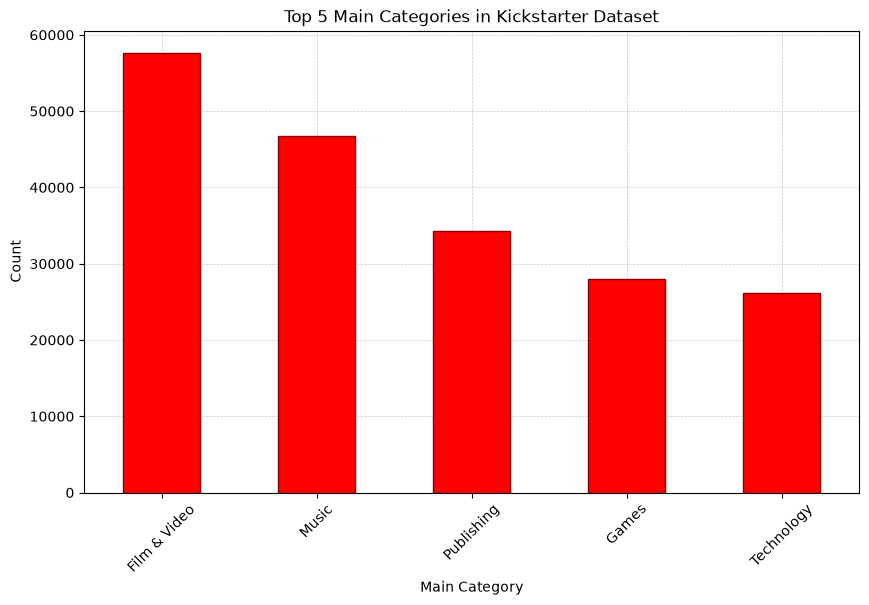

In [45]:
# Filtering the DataFrame to include only the top 5 categories based on their counts.
filtered_df = df[df['main_category'].isin(top_5_main_categories)]  
filtered_df

#Needs to show the 5 categories and their counts.

ax= filtered_df['main_category'].value_counts().plot(kind='bar', figsize=(10, 6), color='red', edgecolor='darkred')
plt.title('Top 5 Main Categories in Kickstarter Dataset')
plt.xlabel('Main Category')
plt.ylabel('Count') 

ax.grid(True, which='major',axis='both', linestyle='--',linewidth=0.5, alpha=0.7)
plt.xticks(rotation=45) 
ax.set_axisbelow(True)

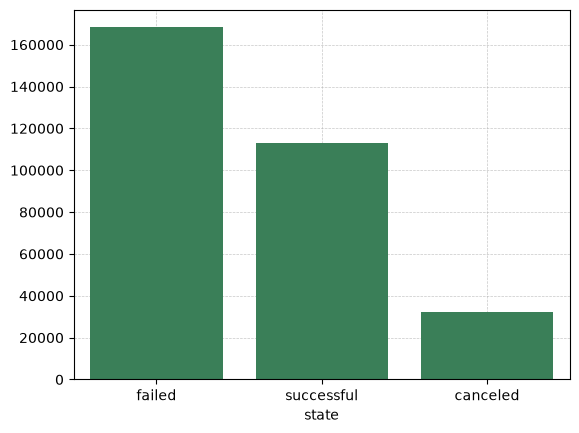

In [46]:
ax= sns.barplot(x=df[df['state'].isin(['successful', 'failed', 'canceled'])]['state']
    .value_counts().index, color='seagreen', y=df[df['state'].isin(['successful', 'failed', 'canceled'])]['state'].value_counts().values)
ax.grid(True, which='major',axis='both', linestyle='--',linewidth=0.5, alpha=0.7)
ax.set_axisbelow(True)

In [47]:
#Need to create a data set for film and video, music, and publishing, and compare the backer trends for each of these categories.

print(df['state'].isin(['successful','failed','canceled']).describe())

count     323750
unique         2
top         True
freq      313656
Name: state, dtype: object


In [48]:
print(df[['goal', 'pledged', 'backers', 'usd pledged']].describe())

print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))


0         goal pledged backers usd pledged
count   323750  323750  323750      323750
unique    8188   55598    3592       94377
top       5000       0       0           0
freq     25520   45784   48863       50462

Missing values:
0
ID               0
name             0
category         0
main_category    0
currency         0
deadline         0
goal             0
launched         0
pledged          0
state            0
backers          0
country          0
usd pledged      0
dtype: int64


In [49]:
# Keep only completed projects with clear successful/failed outcomes
completed = df[df['state'].isin(['successful', 'failed', 'canceled'])].copy()

# Calculate the success rate for each main category
success_rates = (completed.assign(success=completed['state'].eq('successful'))
    .groupby('main_category')['success']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(success_rates.round(2))

main_category
Dance           63.15
Theater         60.66
Comics          52.27
Music           49.58
Art             40.85
Film & Video    38.07
Design          34.43
Games           34.30
Publishing      30.83
Photography     30.46
Food            25.28
Fashion         24.03
Crafts          23.93
Journalism      21.94
Technology      20.12
Name: success, dtype: float64


In [50]:
df['launched'] = pd.to_datetime(df['launched'], errors='coerce')
df['deadline'] = pd.to_datetime(df['deadline'], errors='coerce')

df['campaign_days'] = (df['deadline'] - df['launched']).dt.days

print(df['campaign_days'].describe())

count    323118.000000
mean         34.535851
std          71.180066
min           1.000000
25%          30.000000
50%          30.000000
75%          37.000000
max       16739.000000
Name: campaign_days, dtype: float64


In [51]:
print(df['category'].describe())

count             323750
unique               771
top       Product Design
freq               17477
Name: category, dtype: object


In [52]:
print(df['main_category'].describe())

count           323750
unique             120
top       Film & Video
freq             57679
Name: main_category, dtype: object


In [53]:
print(df['currency'].describe())

count     323750
unique        37
top          USD
freq      260298
Name: currency, dtype: object


In [54]:
print(df['deadline'].describe())

count                        323118
mean     2014-05-18 07:38:15.080150
min             2009-05-03 08:59:59
25%      2013-02-18 21:25:36.750000
50%             2014-09-07 17:59:12
75%      2015-09-09 16:37:25.500000
max             2017-02-04 08:54:55
Name: deadline, dtype: object


In [55]:
print(df['goal'].describe())

count     323750
unique      8188
top         5000
freq       25520
Name: goal, dtype: object


In [56]:
print(df['launched'].describe())

count                        323126
mean     2014-04-13 14:30:42.331155
min             1970-01-01 01:00:00
25%      2013-01-17 06:50:43.750000
50%      2014-08-05 01:18:33.500000
75%             2015-08-06 21:06:54
max             2016-12-06 10:18:31
Name: launched, dtype: object


In [57]:
print(df['pledged'].describe())

count     323750
unique     55598
top            0
freq       45784
Name: pledged, dtype: object


In [58]:
print(df['state'].describe())

count     323750
unique       410
top       failed
freq      168221
Name: state, dtype: object


In [59]:
print(df['backers'].describe())

count     323750
unique      3592
top            0
freq       48863
Name: backers, dtype: object


In [60]:
print(df['country'].describe())



count     323750
unique       162
top           US
freq      257565
Name: country, dtype: object


In [61]:
print(df['usd pledged'].describe())


count     323750
unique     94377
top            0
freq       50462
Name: usd pledged, dtype: object


In [62]:
x= 323750

y= 168221 

z = 113081

a = 32354




A novice hardware founder assumes that running a longer campaign (45-60 days) will yield significantly more total pledged funds than a sandard short campaign (30 days or less) because it gives peope more time to find it. Define you rtwo groups, state your null and alternative hypotheses, and conduct an appropriate hypothesis test (adapting your simulation methods from Lab07). Report your p-value and conclusion. Should founders stretch their campaigns out? 

In [63]:
print(df.columns.tolist())

print(df["state"].value_counts())

print(df[["usd pledged", "launched", "deadline"]].head())

['ID', 'name', 'category', 'main_category', 'currency', 'deadline', 'goal', 'launched', 'pledged', 'state', 'backers', 'country', 'usd pledged', 'campaign_days']
state
failed        168221
successful    113081
canceled       32354
live            4428
undefined       3555
               ...  
296                1
61                 1
179                1
2501               1
2634               1
Name: count, Length: 410, dtype: int64
0 usd pledged            launched            deadline
1           0 2015-08-11 12:12:28 2015-10-09 11:36:00
2         220 2013-01-12 00:20:50 2013-02-26 00:20:50
3           1 2012-03-17 03:24:11 2012-04-16 04:24:11
4        1283 2015-07-04 08:35:03 2015-08-29 01:00:00
5       52375 2016-02-26 13:38:27 2016-04-01 13:38:27


In [64]:
# Identify unexpected campaign states
valid_states = ["failed", "successful", "canceled", "live", "undefined"]

unexpected_states = df[~df["state"].isin(valid_states)]

print("Number of unexpected states:", len(unexpected_states))

display(unexpected_states.head(10))

# Check the data types of our relevant variables
print(df[["campaign_days", "usd pledged"]].dtypes)

# Check campaign duration and pledged amount
print(df[["campaign_days", "usd pledged"]].describe())

Number of unexpected states: 2111


0,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,campaign_days
330,1001732009,DotPen : Redefines drawing and writing for sma...,Product Design,Design,USD,2014-08-09 21:17:10,25000,2014-06-30 21:17:10,39693,suspended,647,US,39693,40.0
900,100524873,PRESIDENT OF THE UNITED STATES (Suspended),Academic,Publishing,USD,2015-10-25 04:54:42,5500,2015-08-26 05:54:42,0,suspended,0,US,0,59.0
962,1005618996,Masters of the Tooniverse Podcast (Suspended),Webseries,Film & Video,USD,2013-07-02 04:30:00,3200,2013-05-30 19:24:22,3226,suspended,24,US,3226,32.0
1025,1006032032,Buddy day in Heidepark Soltau (Suspended),People,Photography,EUR,2015-06-11 11:06:35,200,2015-05-12 11:06:35,13,suspended,3,DE,14.50654855,30.0
1349,10080310,parasuicidal tendancies a performance of rebir...,Art,Art,USD,2010-11-16 18:56:48,1000,2010-10-17 18:56:48,0,suspended,0,US,0,30.0
1455,1008705746,Zephyraï¿½s new full length,'As The World Collapses',Metal,Music,NaT,2016-02-02 00:56:46,NaT,2016-01-03 00:56:46,4262,failed,14,SE,NaN
1564,1009317190,French Cuisine,A Traditional Experience,Cookbooks,Food,NaT,2014-09-08 00:46:23,NaT,2014-08-09 03:16:02,3984,failed,46,US,NaN
1795,1010871699,The Beginners Guide to being Unsuicidal,the one act,Theater,Theater,NaT,2011-12-31 23:25:46,NaT,2011-11-21 23:25:46,525,failed,10,US,NaN
1932,1011687764,Best OnLine Classifieds,Ever / No More Spam,Web,Technology,NaT,2014-09-20 19:56:10,NaT,2014-08-21 19:56:10,0,failed,0,US,NaN
2006,1012101826,Niko makes really good spaghetti (Suspended),Small Batch,Food,USD,2015-06-07 06:03:35,1100,2015-04-08 06:03:35,2,suspended,2,US,2,60.0


0
campaign_days    float64
usd pledged          str
dtype: object
0      campaign_days
count  323118.000000
mean       34.535851
std        71.180066
min         1.000000
25%        30.000000
50%        30.000000
75%        37.000000
max     16739.000000


In [69]:
# Identify observations with invalid numerical values
df["campaign_days"] = pd.to_numeric(
    df["campaign_days"], errors="coerce"
)

df["usd pledged"] = pd.to_numeric(
    df["usd pledged"], errors="coerce"
)

# Identify records missing the variables needed for our investigation
invalid_data = df[
    df["campaign_days"].isna() |
    df["usd pledged"].isna()
]

print("Total observations:", len(df))
print("Observations with missing duration or pledged amount:", len(invalid_data))
print("Data Quality Check Complete!")

display(invalid_data.head(10))

Total observations: 323750
Observations with missing duration or pledged amount: 4422
Data Quality Check Complete!


0,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,campaign_days
151,1000694855,STREETFIGHTERZ WHEELIE MURICA,Film & Video,Film & Video,USD,2014-09-20 06:59:00,6500,2014-08-06 21:28:36,555,undefined,0,"N,""0",NaN,44.0
288,100149523,Duncan Woods - Chameleon EP,Music,Music,AUD,2015-08-25 23:00:00,4500,2015-08-04 12:05:17,4767,undefined,0,"N,""0",NaN,21.0
550,1003023003,The Making of Ashley Kelley's Debut Album,Music,Music,USD,2015-04-09 21:06:13,3500,2015-03-10 20:06:13,3576,undefined,0,"N,""0",NaN,30.0
562,1003130892,Butter Side Down Debut Album,Music,Music,USD,2015-11-26 10:59:00,6000,2015-11-02 22:09:19,7007.8,undefined,0,"N,""0",NaN,23.0
651,1003629045,Chase Goehring debut EP,Music,Music,USD,2016-03-21 06:00:00,3000,2016-02-23 03:09:49,3660.38,undefined,0,"N,""0",NaN,27.0
715,1004013077,Spencer Capier Instrumental Project 2015,Music,Music,CAD,2014-10-10 22:51:01,4000,2014-09-10 22:51:01,4760,undefined,0,"N,""0",NaN,30.0
731,1004126342,LUKAS LIGETI'S 50TH BIRTHDAY FESTIVAL: ORIGINA...,Music,Music,USD,2015-06-11 04:00:00,5000,2015-05-15 02:12:35,6370,undefined,0,"N,""0",NaN,27.0
748,1004255433,The Battle For Breukelen: A Neighborhood Epic,Film & Video,Film & Video,USD,2015-11-07 08:59:00,6000,2015-10-10 18:45:24,6695,undefined,0,"N,""0",NaN,27.0
752,1004298993,"""Tamboura Plays Violin"" - a collection of Pop ...",Music,Music,USD,2015-03-28 18:28:27,2750,2015-02-11 19:28:27,2926,undefined,0,"N,""0",NaN,44.0
766,1004402863,Nightingale Noel - An A Cappella Holiday CD,Music,Music,USD,2015-12-11 21:02:55,1200,2015-11-11 21:02:55,1585,undefined,0,"N,""0",NaN,30.0


In [66]:
# Keep observations with valid numerical values
clean_df = df.dropna(
    subset=["campaign_days", "usd pledged"]
).copy()

# Define our two campaign groups
short_campaigns = clean_df[
    clean_df["campaign_days"] <= 30
]

long_campaigns = clean_df[
    clean_df["campaign_days"].between(45, 60)
]

print("Short campaigns:", len(short_campaigns))
print("Long campaigns:", len(long_campaigns))

Short campaigns: 205310
Long campaigns: 56075



$$H_0: \mu_{\text{long}} = \mu_{\text{short}}$$

$$H_A: \mu_{\text{long}} > \mu_{\text{short}}$$

* Null hypothesis: Longer campaigns do not generate more average pledged funding.
* Alternative hypothesis: Longer campaigns generate more average pledged funding.


In [70]:
# Remove observations missing either variable
clean_df = df.dropna(
    subset=["campaign_days", "usd pledged"]
).copy()

# Group 1: Campaigns lasting 30 days or less
short_campaigns = clean_df[
    clean_df["campaign_days"] <= 30
]

# Group 2: Campaigns lasting 45–60 days
long_campaigns = clean_df[
    clean_df["campaign_days"].between(45, 60)
]

print("Short campaigns:", len(short_campaigns))
print("Long campaigns:", len(long_campaigns))

Short campaigns: 205310
Long campaigns: 56075



$$\bar{x}_{long}-\bar{x}_{short}$$

In [71]:
short_mean = short_campaigns["usd pledged"].mean()
long_mean = long_campaigns["usd pledged"].mean()

observed_difference = long_mean - short_mean

print("Short campaign mean:", round(short_mean, 2))
print("Long campaign mean:", round(long_mean, 2))
print("Observed difference:", round(observed_difference, 2))

Short campaign mean: 6268.75
Long campaign mean: 7781.08
Observed difference: 1512.33


In [72]:
print("Minimum campaign duration:", clean_df["campaign_days"].min())
print("Maximum campaign duration:", clean_df["campaign_days"].max())

print("\nDuration summary:")
print(clean_df["campaign_days"].describe())

Minimum campaign duration: 1.0
Maximum campaign duration: 16739.0

Duration summary:
count    319328.000000
mean         34.558689
std          71.589939
min           1.000000
25%          30.000000
50%          30.000000
75%          38.000000
max       16739.000000
Name: campaign_days, dtype: float64


In [73]:
unusual_campaigns = clean_df[
    clean_df["campaign_days"] > 60
].sort_values("campaign_days", ascending=False)

print("Campaigns longer than 60 days:", len(unusual_campaigns))

display(
    unusual_campaigns[
        ["ID", "name", "category", "main_category",
         "launched", "deadline", "campaign_days", "usd pledged"]
    ].head(10)
)

Campaigns longer than 60 days: 5126


0,ID,name,category,main_category,launched,deadline,campaign_days,usd pledged
272950,69489148,Student Auditions Music 2015,Publishing,Publishing,1970-01-01 01:00:00,2015-10-31 09:17:00,16739.0,0.0
2444,1014746686,Salt of the Earth: A Dead Sea Movie (Canceled),Film & Video,Film & Video,1970-01-01 01:00:00,2010-09-15 02:00:00,14867.0,0.0
41238,1245461087,1st Super-Size Painting - Social Network Owned...,Art,Art,1970-01-01 01:00:00,2010-08-14 21:43:00,14835.0,0.0
80907,1480763647,"Support Solo Theater! Help ""Ungrateful Daughte...",Theater,Theater,1970-01-01 01:00:00,2010-06-01 17:55:00,14761.0,0.0
64542,1384087152,"""ICHOR"" (Canceled)",Film & Video,Film & Video,1970-01-01 01:00:00,2010-05-21 00:12:00,14749.0,0.0
212156,330942060,"Help RIZ Make A Charity Album: 8 Songs, 8 Caus...",Music,Music,1970-01-01 01:00:00,2010-05-04 12:54:00,14733.0,0.0
234253,462917959,Identity Communications Infographic (Canceled),Design,Design,1970-01-01 01:00:00,2010-04-10 13:30:00,14709.0,0.0
63525,1378129953,SmoothnFusion Jazz Comedy Album,Jazz,Music,2010-12-30 00:53:47,2011-04-01 00:53:47,92.0,146.0
204074,282190697,'Do What You Love' Live your Dreams - a P. J...,Documentary,Film & Video,2011-01-02 07:16:22,2011-04-04 07:16:22,92.0,0.0
208311,307797738,Angie McClure's new album,Indie Rock,Music,2011-01-02 07:39:52,2011-04-04 07:39:52,92.0,5275.0


In [74]:
display(unusual_campaigns[
    ["ID", "name", "category", "main_category",
     "launched", "deadline", "campaign_days", "usd pledged"]
].head(10))

0,ID,name,category,main_category,launched,deadline,campaign_days,usd pledged
272950,69489148,Student Auditions Music 2015,Publishing,Publishing,1970-01-01 01:00:00,2015-10-31 09:17:00,16739.0,0.0
2444,1014746686,Salt of the Earth: A Dead Sea Movie (Canceled),Film & Video,Film & Video,1970-01-01 01:00:00,2010-09-15 02:00:00,14867.0,0.0
41238,1245461087,1st Super-Size Painting - Social Network Owned...,Art,Art,1970-01-01 01:00:00,2010-08-14 21:43:00,14835.0,0.0
80907,1480763647,"Support Solo Theater! Help ""Ungrateful Daughte...",Theater,Theater,1970-01-01 01:00:00,2010-06-01 17:55:00,14761.0,0.0
64542,1384087152,"""ICHOR"" (Canceled)",Film & Video,Film & Video,1970-01-01 01:00:00,2010-05-21 00:12:00,14749.0,0.0
212156,330942060,"Help RIZ Make A Charity Album: 8 Songs, 8 Caus...",Music,Music,1970-01-01 01:00:00,2010-05-04 12:54:00,14733.0,0.0
234253,462917959,Identity Communications Infographic (Canceled),Design,Design,1970-01-01 01:00:00,2010-04-10 13:30:00,14709.0,0.0
63525,1378129953,SmoothnFusion Jazz Comedy Album,Jazz,Music,2010-12-30 00:53:47,2011-04-01 00:53:47,92.0,146.0
204074,282190697,'Do What You Love' Live your Dreams - a P. J...,Documentary,Film & Video,2011-01-02 07:16:22,2011-04-04 07:16:22,92.0,0.0
208311,307797738,Angie McClure's new album,Indie Rock,Music,2011-01-02 07:39:52,2011-04-04 07:39:52,92.0,5275.0


In [75]:
epoch_rows = clean_df[
    clean_df["launched"] == pd.Timestamp("1970-01-01")
]

print("Rows with 1970 launch date:", len(epoch_rows))

Rows with 1970 launch date: 0


In [76]:
epoch_rows = clean_df[
    clean_df["launched"].dt.date == pd.Timestamp("1970-01-01").date()
]

print("Rows with 1970 launch date:", len(epoch_rows))

display(epoch_rows[
    ["ID", "name", "launched", "deadline", "campaign_days"]
].head(10))

Rows with 1970 launch date: 7


0,ID,name,launched,deadline,campaign_days
2444,1014746686,Salt of the Earth: A Dead Sea Movie (Canceled),1970-01-01 01:00:00,2010-09-15 02:00:00,14867.0
41238,1245461087,1st Super-Size Painting - Social Network Owned...,1970-01-01 01:00:00,2010-08-14 21:43:00,14835.0
64542,1384087152,"""ICHOR"" (Canceled)",1970-01-01 01:00:00,2010-05-21 00:12:00,14749.0
80907,1480763647,"Support Solo Theater! Help ""Ungrateful Daughte...",1970-01-01 01:00:00,2010-06-01 17:55:00,14761.0
212156,330942060,"Help RIZ Make A Charity Album: 8 Songs, 8 Caus...",1970-01-01 01:00:00,2010-05-04 12:54:00,14733.0
234253,462917959,Identity Communications Infographic (Canceled),1970-01-01 01:00:00,2010-04-10 13:30:00,14709.0
272950,69489148,Student Auditions Music 2015,1970-01-01 01:00:00,2015-10-31 09:17:00,16739.0


In [77]:
epoch_rows = clean_df[
    clean_df["launched"].dt.date == pd.Timestamp("1970-01-01").date()
]

print("Rows with 1970 launch date:", len(epoch_rows))

display(epoch_rows[
    ["ID", "name", "launched", "deadline", "campaign_days"]
].head(10))

Rows with 1970 launch date: 7


0,ID,name,launched,deadline,campaign_days
2444,1014746686,Salt of the Earth: A Dead Sea Movie (Canceled),1970-01-01 01:00:00,2010-09-15 02:00:00,14867.0
41238,1245461087,1st Super-Size Painting - Social Network Owned...,1970-01-01 01:00:00,2010-08-14 21:43:00,14835.0
64542,1384087152,"""ICHOR"" (Canceled)",1970-01-01 01:00:00,2010-05-21 00:12:00,14749.0
80907,1480763647,"Support Solo Theater! Help ""Ungrateful Daughte...",1970-01-01 01:00:00,2010-06-01 17:55:00,14761.0
212156,330942060,"Help RIZ Make A Charity Album: 8 Songs, 8 Caus...",1970-01-01 01:00:00,2010-05-04 12:54:00,14733.0
234253,462917959,Identity Communications Infographic (Canceled),1970-01-01 01:00:00,2010-04-10 13:30:00,14709.0
272950,69489148,Student Auditions Music 2015,1970-01-01 01:00:00,2015-10-31 09:17:00,16739.0


In [78]:
analysis_df = clean_df[
    clean_df["launched"].dt.date != pd.Timestamp("1970-01-01").date()
].copy()

print("Original cleaned dataset:", len(clean_df))
print("Dataset after removing malformed dates:", len(analysis_df))

Original cleaned dataset: 319328
Dataset after removing malformed dates: 319321


In [79]:
short_campaigns = analysis_df[
    analysis_df["campaign_days"] <= 30
]

long_campaigns = analysis_df[
    analysis_df["campaign_days"].between(45, 60)
]

print("Short campaigns:", len(short_campaigns))
print("Long campaigns:", len(long_campaigns))

Short campaigns: 205310
Long campaigns: 56075


In [80]:
short_mean = short_campaigns["usd pledged"].mean()
long_mean = long_campaigns["usd pledged"].mean()

observed_difference = long_mean - short_mean

print("Short campaign mean:", round(short_mean, 2))
print("Long campaign mean:", round(long_mean, 2))
print("Observed difference:", round(observed_difference, 2))

Short campaign mean: 6268.75
Long campaign mean: 7781.08
Observed difference: 1512.33


In [82]:
short_values = short_campaigns["usd pledged"].to_numpy()
long_values = long_campaigns["usd pledged"].to_numpy()

pooled = np.concatenate([short_values, long_values])

n_short = len(short_values)
n_simulations = 5000

rng = np.random.default_rng(42)

simulated_differences = np.empty(n_simulations)

for i in range(n_simulations):
    shuffled = rng.permutation(pooled)

    simulated_short = shuffled[:n_short]
    simulated_long = shuffled[n_short:]

    simulated_differences[i] = (
        simulated_long.mean() - simulated_short.mean()
    )

p_value = (
    np.sum(simulated_differences >= observed_difference) + 1
) / (n_simulations + 1)

print("Observed difference:", observed_difference)
print("Randomization p-value:", p_value)

Observed difference: 1512.327202369911
Randomization p-value: 0.0001999600079984003


Given our hypothesis test: We reject the null hypothesis!

$$\alpha=0.05\:$$

$$p=0.0001999600079984003<0.05$$

However, Kickstarter funding amounts are likely highly skewed: a relatively small number of campaigns may raise exceptionally large amounts. Our permutation procedure also assumes exchangeability of the observations under the null, which is stronger than simply assuming equal population means.

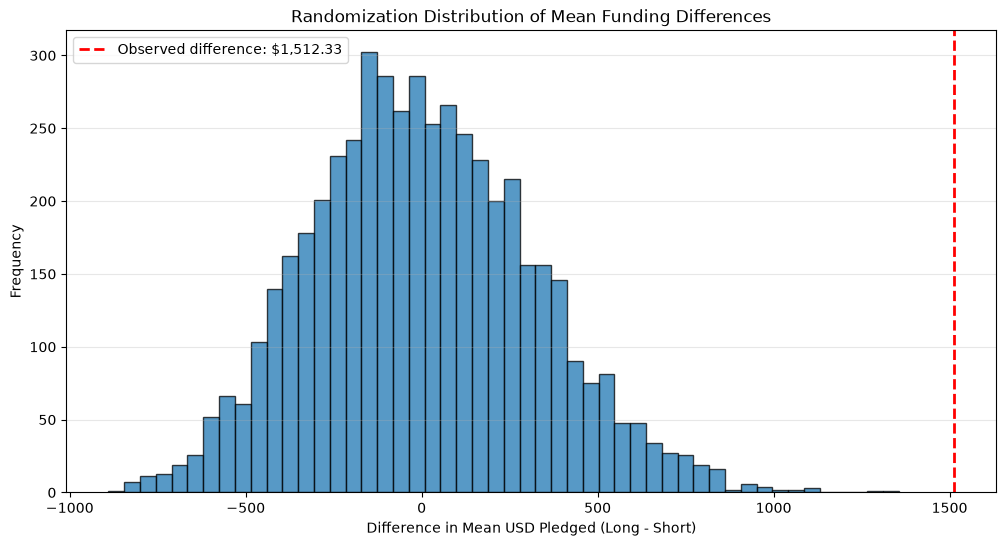

In [83]:
plt.figure(figsize=(12, 6))

plt.hist(
    simulated_differences,
    bins=50,
    edgecolor="black",
    alpha=0.75
)

# Mark the actual observed difference
plt.axvline(
    observed_difference,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Observed difference: ${observed_difference:,.2f}"
)

plt.title("Randomization Distribution of Mean Funding Differences")
plt.xlabel("Difference in Mean USD Pledged (Long - Short)")
plt.ylabel("Frequency")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

In [84]:
short_values = short_campaigns["usd pledged"].to_numpy()
long_values = long_campaigns["usd pledged"].to_numpy()

pooled = np.concatenate([short_values, long_values])

n_short = len(short_values)
n_simulations = 20000

rng = np.random.default_rng(42)

simulated_differences = np.empty(n_simulations)

for i in range(n_simulations):
    shuffled = rng.permutation(pooled)

    simulated_short = shuffled[:n_short]
    simulated_long = shuffled[n_short:]

    simulated_differences[i] = (
        simulated_long.mean() - simulated_short.mean()
    )

p_value = (
    np.sum(simulated_differences >= observed_difference) + 1
) / (n_simulations + 1)

print("Number of simulations:", n_simulations)
print("Observed difference:", round(observed_difference, 2))
print("Simulations as extreme or more extreme:",
      np.sum(simulated_differences >= observed_difference))
print("Estimated p-value:", p_value)

Number of simulations: 20000
Observed difference: 1512.33
Simulations as extreme or more extreme: 0
Estimated p-value: 4.999750012499375e-05


$$P= 0.00004999750012499375$$



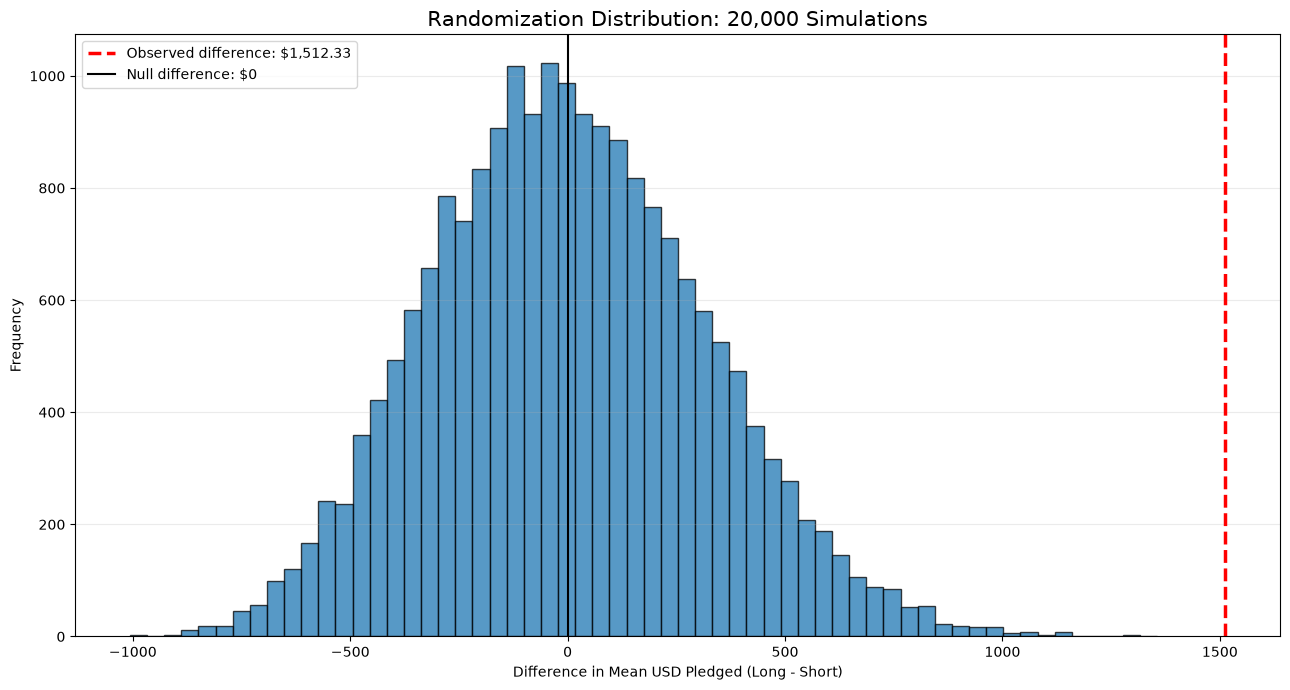

In [85]:
plt.figure(figsize=(13, 7))

plt.hist(
    simulated_differences,
    bins=60,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    observed_difference,
    color="red",
    linestyle="--",
    linewidth=2.5,
    label=f"Observed difference: ${observed_difference:,.2f}"
)

plt.axvline(
    0,
    color="black",
    linestyle="-",
    linewidth=1.5,
    label="Null difference: $0"
)

plt.title(
    "Randomization Distribution: 20,000 Simulations",
    fontsize=15
)

plt.xlabel("Difference in Mean USD Pledged (Long - Short)")
plt.ylabel("Frequency")

plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

In [86]:
funding_summary = pd.DataFrame({
    "Short campaigns (≤30 days)": short_campaigns["usd pledged"].describe(),
    "Long campaigns (45–60 days)": long_campaigns["usd pledged"].describe()
})

display(funding_summary.round(2))

,Short campaigns (≤30 days),Long campaigns (45–60 days)
count,205310.00,56075.00
mean,6268.75,7781.08
std,56655.34,92167.76
min,0.00,0.00
25%,20.00,10.00
50%,460.00,255.00
75%,3150.00,2500.00
max,8782571.99,13285226.36


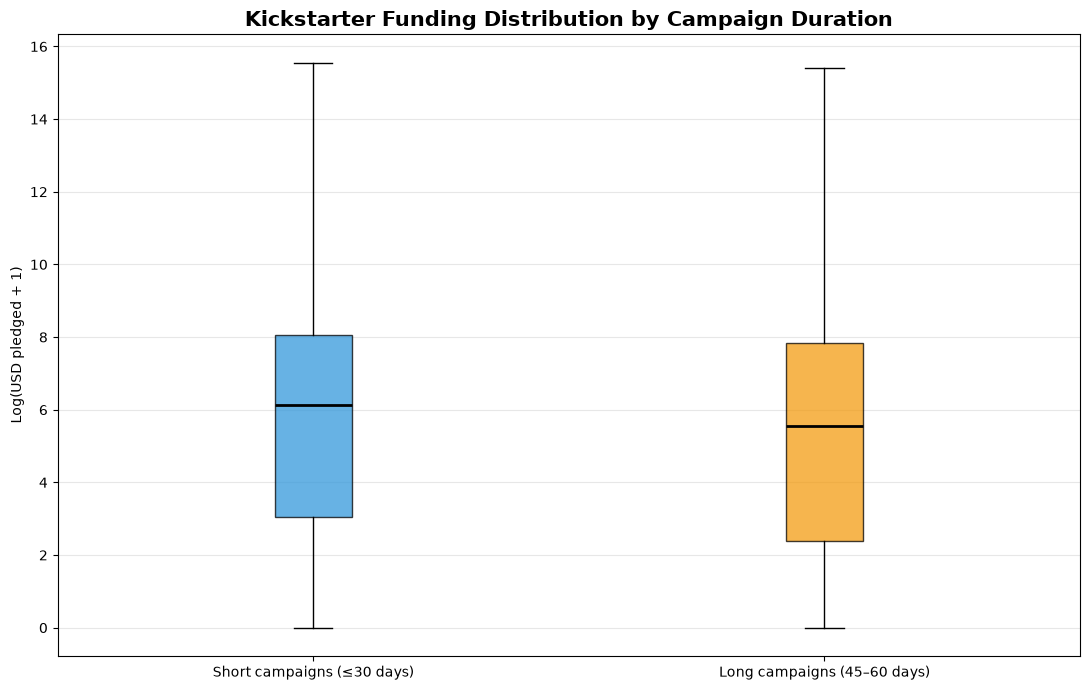

In [96]:
plt.figure(figsize=(11, 7))

boxplot = plt.boxplot(
    [
        np.log1p(short_campaigns["usd pledged"]),
        np.log1p(long_campaigns["usd pledged"])
    ],
    tick_labels=[
        "Short campaigns (≤30 days)",
        "Long campaigns (45–60 days)"
    ],
    showfliers=False,
    patch_artist=True
)

# Color the boxes
colors = ["#3498DB", "#F39C12"]

for patch, color in zip(boxplot["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

# Style median lines
for median in boxplot["medians"]:
    median.set_color("black")
    median.set_linewidth(2)

plt.title(
    "Kickstarter Funding Distribution by Campaign Duration",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Log(USD pledged + 1)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

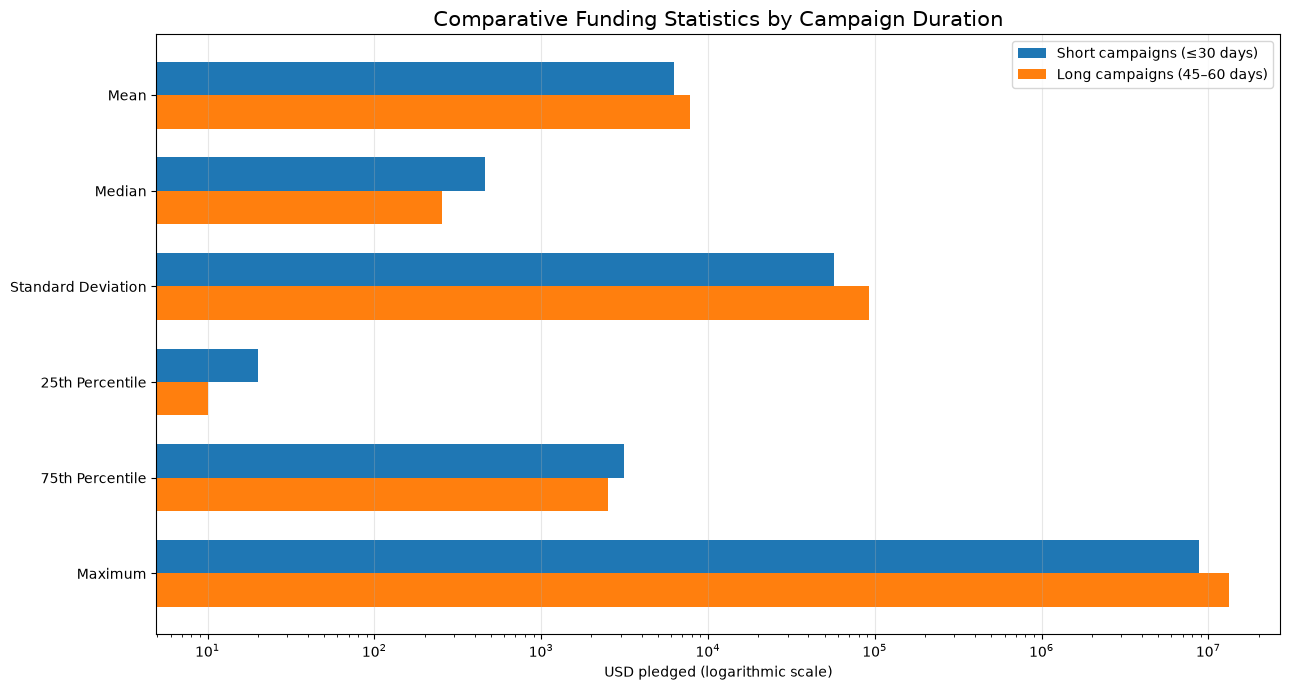

In [87]:
# Summary statistics
statistics = {
    "Mean": [short_mean, long_mean],
    "Median": [
        short_campaigns["usd pledged"].median(),
        long_campaigns["usd pledged"].median()
    ],
    "Standard Deviation": [
        short_campaigns["usd pledged"].std(),
        long_campaigns["usd pledged"].std()
    ],
    "25th Percentile": [
        short_campaigns["usd pledged"].quantile(0.25),
        long_campaigns["usd pledged"].quantile(0.25)
    ],
    "75th Percentile": [
        short_campaigns["usd pledged"].quantile(0.75),
        long_campaigns["usd pledged"].quantile(0.75)
    ],
    "Maximum": [
        short_campaigns["usd pledged"].max(),
        long_campaigns["usd pledged"].max()
    ]
}

labels = list(statistics.keys())
short_values = [statistics[x][0] for x in labels]
long_values = [statistics[x][1] for x in labels]

# Create visualization
fig, ax = plt.subplots(figsize=(13, 7))

y = np.arange(len(labels))
height = 0.35

ax.barh(
    y - height/2,
    short_values,
    height,
    label="Short campaigns (≤30 days)"
)

ax.barh(
    y + height/2,
    long_values,
    height,
    label="Long campaigns (45–60 days)"
)

ax.set_xscale("log")
ax.set_yticks(y)
ax.set_yticklabels(labels)

ax.set_xlabel("USD pledged (logarithmic scale)")
ax.set_title(
    "Comparative Funding Statistics by Campaign Duration",
    fontsize=15
)

ax.legend()
ax.grid(axis="x", alpha=0.3)
ax.invert_yaxis()

plt.tight_layout()
plt.show()

In [97]:
def funding_sensitivity(series):
    series = series.dropna()

    # Identify the top 1% of observations
    n_top = int(np.ceil(len(series) * 0.01))
    top_campaigns = series.nlargest(n_top)

    # Remove those observations temporarily
    remaining = series.drop(top_campaigns.index)

    return {
        "Original mean": series.mean(),
        "Median": series.median(),
        "Top 1% funding share": top_campaigns.sum() / series.sum() * 100,
        "Mean without top 1%": remaining.mean(),
        "Campaigns examined": len(series),
        "Campaigns excluded temporarily": n_top
    }

sensitivity_results = pd.DataFrame({
    "Short campaigns": funding_sensitivity(
        short_campaigns["usd pledged"]
    ),
    "Long campaigns": funding_sensitivity(
        long_campaigns["usd pledged"]
    )
})

display(sensitivity_results.round(2))

,Short campaigns,Long campaigns
Original mean,6268.75,7781.08
Median,460.00,255.00
Top 1% funding share,43.56,53.15
Mean without top 1%,3573.66,3682.05
Campaigns examined,205310.00,56075.00
Campaigns excluded temporarily,2054.00,561.00


In [98]:
short_median = short_campaigns["usd pledged"].median()
long_median = long_campaigns["usd pledged"].median()

median_difference = long_median - short_median

print("Short campaign median:", short_median)
print("Long campaign median:", long_median)
print("Median difference:", median_difference)

Short campaign median: 460.0
Long campaign median: 255.0
Median difference: -205.0


NOTE:

* Long campaigns have higher average funding.
* Short campaigns have higher median funding.
* Removing the top 1% of funding observations reduces the difference between the means by approximately 92.8%.